# Business Analytics Case Study

**Student:** VimalHariHar S K
**Register Number:** CB.SC.U4CSE23254
**Class / Section:** B.Tech CSE - Section C
**Topic:** Building India's Missing Poultry Price Panel: Forecasting NECC Egg Prices with a Walk-Forward Validated Baseline

This notebook runs the full analysis pipeline for the case study end to end: loading the scraped NECC egg-price panel and the FRED feed-cost series, cleaning and feature-engineering the data, exploratory analysis, walk-forward predictive modelling (Ridge and XGBoost against two naive baselines), and the Granger-causality test. Every output below is produced by running the project's own pipeline code (`src/`), not hand-entered.

## 1. Import Libraries

In [1]:
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

# Make the project's own pipeline modules importable from notebooks/
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))

from features.build_panel import load_egg, load_feed, build as build_feature_panel
from models.forecast import (
    FEATURES, walk_forward_splits, fit_predict, score, causality_tests, load_panel,
)

%matplotlib inline

# Run everything relative to the repo root so paths match the pipeline scripts.
os.chdir(os.path.abspath(".."))
print("cwd:", os.getcwd())

cwd: /private/tmp/claude-501/-Users-abinayasivanesan/83527486-16c3-410b-a2d4-57aab262c69c/scratchpad/poultry-cobweb-early-warning


## 2. Load the Collected Dataset

The primary dataset is collected by web scraping the NECC daily zonal egg-rate sheet
(`e2necc.com/home/eggprice`), one HTTP POST per month from January 2009 to July 2026
(`src/scrapers/egg_rates.py`, run via `scripts/backfill_egg.py`). No survey/questionnaire
was used, and no ready-made Kaggle/UCI/GitHub dataset was used as the primary source.

A secondary series -- monthly global maize and soybean prices from FRED
(`src/scrapers/feed_prices.py`) -- is used to build a feed-cost index as an explanatory
variable.

In [2]:
EGG_PATH = os.path.join("data", "processed", "egg_panel.csv")
FEED_PATH = os.path.join("data", "raw", "feed_fred.csv")

egg_raw = pd.read_csv(EGG_PATH, parse_dates=["date"])
feed_raw = pd.read_csv(FEED_PATH, parse_dates=["date"])

print("Egg panel shape:", egg_raw.shape)
display(egg_raw.head())

print("\nFeed panel shape:", feed_raw.shape)
display(feed_raw.head())

Egg panel shape: (196168, 5)


,zone,date,egg_price,source_url,retrieved_at
0,Ahmedabad,2009-01-01,204.0,https://e2necc.com/home/eggprice,2026-09-25T12:36:24.180708+00:00
1,Ahmedabad,2009-01-02,206.0,https://e2necc.com/home/eggprice,2026-09-25T12:36:24.180708+00:00
2,Ahmedabad,2009-01-03,208.0,https://e2necc.com/home/eggprice,2026-09-25T12:36:24.180708+00:00
3,Ahmedabad,2009-01-04,210.0,https://e2necc.com/home/eggprice,2026-09-25T12:36:24.180708+00:00
4,Ahmedabad,2009-01-05,210.0,https://e2necc.com/home/eggprice,2026-09-25T12:36:24.180708+00:00



Feed panel shape: (415, 4)


,date,maize_usd_mt,soy_usd_mt,retrieved_at
0,1992-01-01,109.586357,208.610226,2026-09-25T12:37:33.193804+00:00
1,1992-02-01,113.921257,211.159575,2026-09-25T12:37:33.193804+00:00
2,1992-03-01,116.684593,216.143437,2026-09-25T12:37:33.193804+00:00
3,1992-04-01,109.055138,211.297378,2026-09-25T12:37:33.193804+00:00
4,1992-05-01,109.177910,220.369384,2026-09-25T12:37:33.193804+00:00


## 3. Initial Data Inspection

In [3]:
print("Egg panel -- rows and columns:", egg_raw.shape)
print("Zones:", egg_raw['zone'].nunique())
print("Date range:", egg_raw['date'].min().date(), "->", egg_raw['date'].max().date())

print("\nData types:")
display(egg_raw.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(egg_raw.isna().sum().to_frame("missing"))

Egg panel -- rows and columns: (196168, 5)
Zones: 37
Date range: 2009-01-01 -> 2026-07-31

Data types:


,dtype
zone,object
date,datetime64[ns]
egg_price,float64
source_url,object
retrieved_at,object



Missing values:


,missing
zone,0
date,0
egg_price,0
source_url,0
retrieved_at,0


## 4. Data Cleaning and Preprocessing

Steps applied (see `src/features/build_panel.py::load_egg`):
1. Keep only `zone`, `date`, `egg_price`; drop any rows with missing values.
2. Range validation: keep prices strictly between 0 and 2000 paise per egg (removes parsing
   artefacts without trimming genuine extremes).
3. Sort by zone and date so all later lag/rolling features never cross a zone boundary.

Blank/non-numeric cells (holidays, days with no declared rate) were already dropped at
scrape time rather than interpolated, so no price is invented.

In [4]:
before = len(egg_raw)
egg_clean = load_egg()  # applies the range validation + sort described above
after = len(egg_clean)

print(f"Rows before cleaning : {before:,}")
print(f"Rows after cleaning  : {after:,}")
print(f"Rows dropped         : {before - after:,}")
display(egg_clean.describe())

Rows before cleaning : 196,168
Rows after cleaning  : 196,168
Rows dropped         : 0


,date,egg_price
count,196168,196168.000000
mean,2018-02-22 17:09:12.603890176,391.064577
min,2009-01-01 00:00:00,100.000000
25%,2013-09-24 00:00:00,305.000000
50%,2018-05-17 00:00:00,382.000000
75%,2022-08-19 00:00:00,470.000000
max,2026-07-31 00:00:00,890.000000
std,NaN,114.572700


## 5. Feature Engineering

The daily egg panel is joined to the monthly feed-cost index (by year-month) and enriched
with lag, moving-average, year-on-year, return, and calendar features, plus the modelling
target: the egg price 30 days ahead within the same zone
(`src/features/build_panel.py::build`).

In [5]:
analysis_panel = build_feature_panel(horizon=30)

print("Model-ready panel shape:", analysis_panel.shape)
print("Feed coverage:", f"{analysis_panel['feed_cost_index'].notna().mean():.1%}")
display(analysis_panel.head())

# Persist so the rest of the project (figures, reports) stays in sync with this run.
analysis_panel.to_csv(os.path.join("data", "processed", "analysis_panel.csv"), index=False)

Model-ready panel shape: (196168, 19)
Feed coverage: 100.0%


,zone,date,egg_price,maize_usd_mt,soy_usd_mt,feed_cost_index,egg_ma7,egg_ma30,egg_lag1,egg_lag7,egg_lag30,egg_yoy,egg_ret30,day_of_week,month,doy,sin_doy,cos_doy,target
0,Ahmedabad,2009-01-01,204.0,173.29513,364.717966,1.058079,204.0,204.0,NaN,NaN,NaN,NaN,NaN,3,1,1,0.017202,0.999852,193.0
1,Ahmedabad,2009-01-02,206.0,173.29513,364.717966,1.058079,205.0,205.0,204.0,NaN,NaN,NaN,NaN,4,1,2,0.034398,0.999408,193.0
2,Ahmedabad,2009-01-03,208.0,173.29513,364.717966,1.058079,206.0,206.0,206.0,NaN,NaN,NaN,NaN,5,1,3,0.051584,0.998669,193.0
3,Ahmedabad,2009-01-04,210.0,173.29513,364.717966,1.058079,207.0,207.0,208.0,NaN,NaN,NaN,NaN,6,1,4,0.068755,0.997634,186.0
4,Ahmedabad,2009-01-05,210.0,173.29513,364.717966,1.058079,207.6,207.6,210.0,NaN,NaN,NaN,NaN,0,1,5,0.085906,0.996303,186.0


## 6. Descriptive Statistics

In [6]:
numeric_cols = ["egg_price", "maize_usd_mt", "soy_usd_mt", "feed_cost_index",
                "egg_ma7", "egg_ma30", "egg_lag1", "egg_lag30", "egg_yoy", "egg_ret30"]
display(analysis_panel[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
egg_price,196168.0,391.064577,114.572700,100.000000,305.000000,382.000000,470.000000,890.000000
maize_usd_mt,196168.0,212.960251,56.632095,143.989244,166.092424,195.781879,264.573147,348.507117
soy_usd_mt,196168.0,426.938380,84.985394,305.310919,356.925677,398.088762,501.827083,622.913550
feed_cost_index,196168.0,1.281224,0.308823,0.884781,1.007960,1.184283,1.541056,2.024586
egg_ma7,196168.0,390.878813,114.161716,163.666667,304.428571,382.571429,470.571429,778.571429
egg_ma30,196168.0,389.982504,111.875190,163.666667,305.500000,382.333333,469.475000,741.166667
egg_lag1,196131.0,391.032952,114.556987,100.000000,305.000000,382.000000,470.000000,890.000000
egg_lag30,195058.0,389.496309,112.842137,100.000000,304.000000,381.000000,470.000000,890.000000
egg_yoy,183119.0,378.602302,105.787501,100.000000,300.000000,371.000000,452.000000,890.000000
egg_ret30,195058.0,0.015445,0.139600,-0.729730,-0.080000,0.014286,0.107895,1.500000


## 7. Exploratory Data Analysis

### 7.1 National mean price and feed-cost index over time

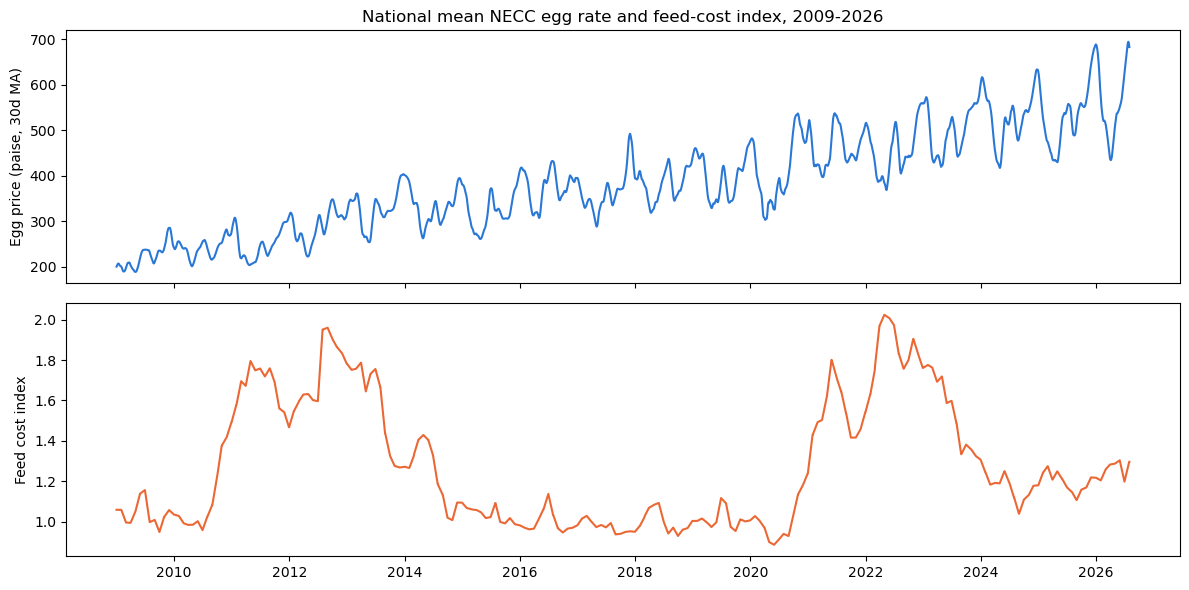

In [7]:
national = (analysis_panel.groupby("date")[["egg_price", "feed_cost_index"]]
            .mean().rolling(30, min_periods=1).mean())

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(national.index, national["egg_price"], color="#2a78d6")
axes[0].set_ylabel("Egg price (paise, 30d MA)")
axes[0].set_title("National mean NECC egg rate and feed-cost index, 2009-2026")
axes[1].plot(national.index, national["feed_cost_index"], color="#eb6834")
axes[1].set_ylabel("Feed cost index")
plt.tight_layout()
plt.show()

### 7.2 Seasonal (within-year) price profile

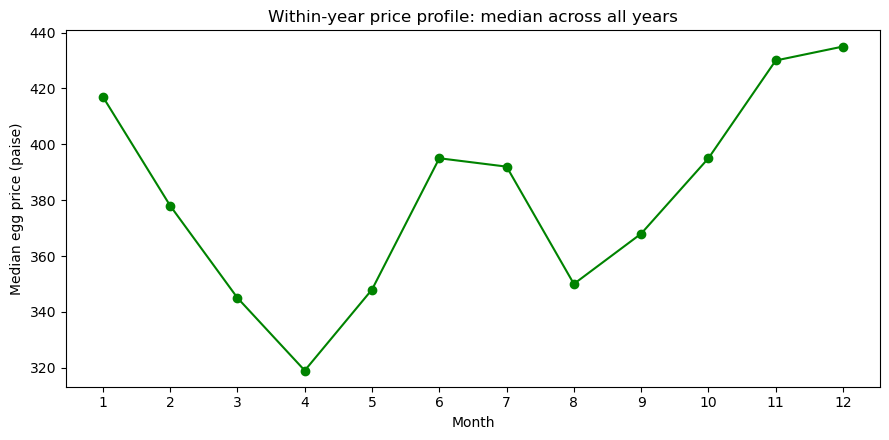

Peak month: 12 (435 paise)
Trough month: 4 (319 paise)
Peak vs annual mean: +14.2%


In [8]:
analysis_panel["month"] = analysis_panel["date"].dt.month
monthly_profile = analysis_panel.groupby("month")["egg_price"].median()

plt.figure(figsize=(9, 4.5))
plt.plot(monthly_profile.index, monthly_profile.values, marker="o", color="#008300")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Median egg price (paise)")
plt.title("Within-year price profile: median across all years")
plt.tight_layout()
plt.show()

peak, trough = monthly_profile.idxmax(), monthly_profile.idxmin()
swing = (monthly_profile.max() - monthly_profile.mean()) / monthly_profile.mean() * 100
print(f"Peak month: {peak} ({monthly_profile.max():.0f} paise)")
print(f"Trough month: {trough} ({monthly_profile.min():.0f} paise)")
print(f"Peak vs annual mean: {swing:+.1f}%")

### 7.3 Regional price structure (zone premium vs national rate)

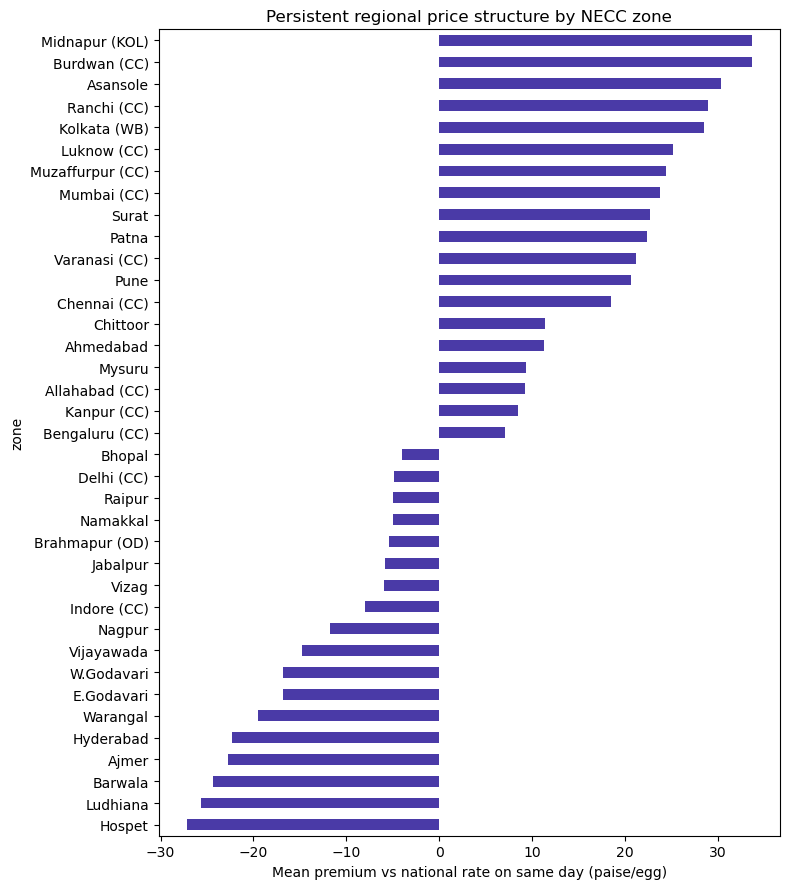

Spread (cheapest to dearest zone): 61 paise/egg


In [9]:
daily_national = analysis_panel.groupby("date")["egg_price"].transform("mean")
analysis_panel["premium"] = analysis_panel["egg_price"] - daily_national
zone_premium = analysis_panel.groupby("zone")["premium"].mean().sort_values()

plt.figure(figsize=(8, 9))
zone_premium.plot(kind="barh", color="#4a3aa7")
plt.xlabel("Mean premium vs national rate on same day (paise/egg)")
plt.title("Persistent regional price structure by NECC zone")
plt.tight_layout()
plt.show()

print(f"Spread (cheapest to dearest zone): {zone_premium.max() - zone_premium.min():.0f} paise/egg")

### 7.4 30-day drawdown distribution (the price-crash risk)

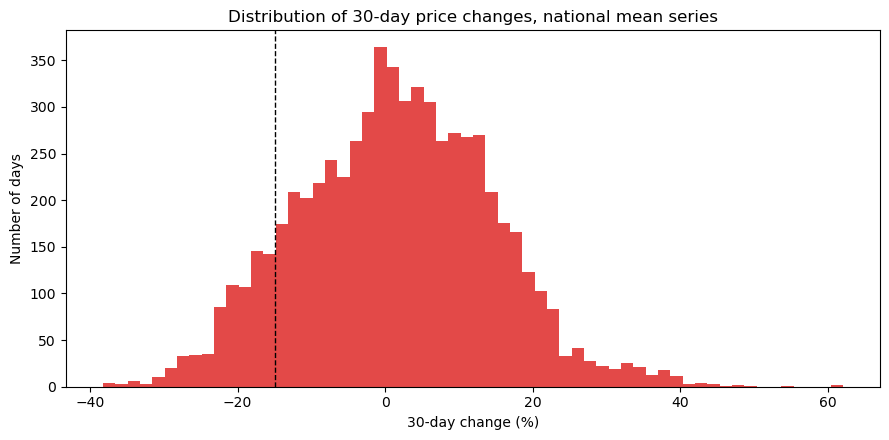

Share of days inside a >=15% 30-day drawdown: 11.3%


In [10]:
nat = analysis_panel.groupby("date")["egg_price"].mean().sort_index()
drawdown_30d = nat / nat.shift(30) - 1.0
crash_share = (drawdown_30d <= -0.15).mean() * 100

plt.figure(figsize=(9, 4.5))
plt.hist(drawdown_30d.dropna() * 100, bins=60, color="#e34948")
plt.axvline(-15, color="black", linestyle="--", linewidth=1)
plt.xlabel("30-day change (%)")
plt.ylabel("Number of days")
plt.title("Distribution of 30-day price changes, national mean series")
plt.tight_layout()
plt.show()

print(f"Share of days inside a >=15% 30-day drawdown: {crash_share:.1f}%")

## 8. Correlation Analysis

Correlation indicates association; it does not by itself establish causation -- the
Granger-causality test in Section 10 addresses causation directly.

,egg_price,maize_usd_mt,soy_usd_mt,feed_cost_index,egg_ma7,egg_ma30,egg_lag1,egg_lag30,egg_yoy,egg_ret30
egg_price,1.000000,0.037347,0.053288,0.042040,0.993885,0.962373,0.997818,0.882700,0.880450,0.231178
maize_usd_mt,0.037347,1.000000,0.891522,0.993750,0.037019,0.037455,0.037052,0.031273,-0.068073,0.005269
soy_usd_mt,0.053288,0.891522,1.000000,0.936514,0.053680,0.055850,0.053234,0.051969,-0.059293,-0.002897
feed_cost_index,0.042040,0.993750,0.936514,1.000000,0.041883,0.042755,0.041799,0.037013,-0.067286,0.003366
egg_ma7,0.993885,0.037019,0.053680,0.041883,1.000000,0.975900,0.996574,0.896171,0.885277,0.192627
egg_ma30,0.962373,0.037455,0.055850,0.042755,0.975900,1.000000,0.966191,0.957702,0.889246,0.007399
egg_lag1,0.997818,0.037052,0.053234,0.041799,0.996574,0.966191,1.000000,0.886041,0.881232,0.220380
egg_lag30,0.882700,0.031273,0.051969,0.037013,0.896171,0.957702,0.886041,1.000000,0.839689,-0.233993
egg_yoy,0.880450,-0.068073,-0.059293,-0.067286,0.885277,0.889246,0.881232,0.839689,1.000000,0.082006
egg_ret30,0.231178,0.005269,-0.002897,0.003366,0.192627,0.007399,0.220380,-0.233993,0.082006,1.000000


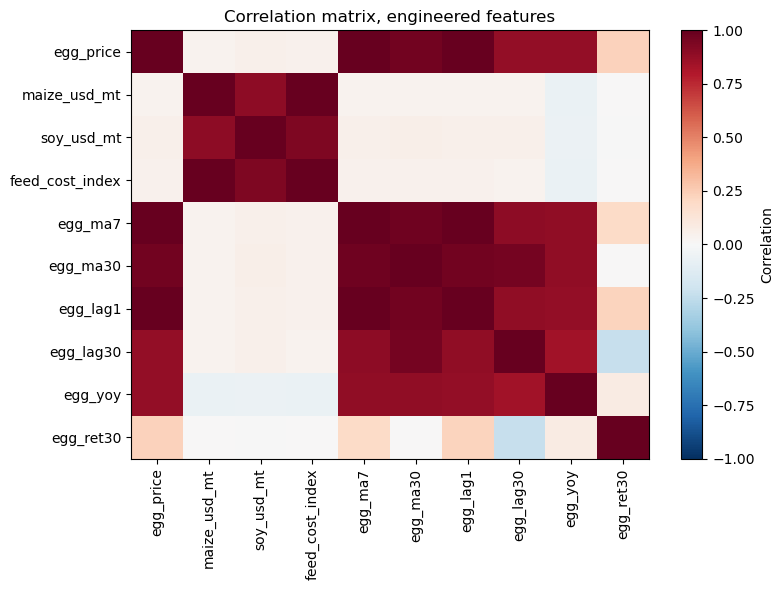

In [11]:
corr = analysis_panel[numeric_cols].corr()
display(corr)

plt.figure(figsize=(8, 6))
plt.imshow(corr, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation matrix, engineered features")
plt.tight_layout()
plt.show()

## 9. Predictive Modelling: Walk-Forward Validation

Task: predict the zonal egg price 30 days ahead from information available on the day the
forecast is made. Two models from the Business Analytics syllabus (Ridge regression,
gradient-boosted trees / XGBoost) are compared against two naive baselines --
persistence (`price[t+30] = price[t]`) and seasonal naive (`price[t+30] = price[t+30-365]`)
-- using 5-fold walk-forward (rolling-origin) validation. Random k-fold is not used because
it would leak future observations into training on time-series data.

In [12]:
panel = load_panel(horizon=30)
print(f"Modelling panel: {len(panel):,} rows | {panel['zone'].nunique()} zones | "
      f"{panel['date'].min().date()} -> {panel['date'].max().date()}")

rows = []
for k, tr, te in walk_forward_splits(panel["date"], folds=5):
    Xtr, ytr = panel.loc[tr, FEATURES].values, panel.loc[tr, "target"].values
    Xte, yte = panel.loc[te, FEATURES].values, panel.loc[te, "target"].values
    if len(Xtr) < 1000 or len(Xte) == 0:
        continue

    fold_pred = {
        "naive_persist": panel.loc[te, "egg_price"].values,
        "naive_seasonal": panel.loc[te, "egg_yoy"].values,
    }
    for name in ("ridge", "xgboost"):
        _, p = fit_predict(name, Xtr, ytr, Xte)
        fold_pred[name] = p

    for name, p in fold_pred.items():
        s = score(yte, p)
        s.update(fold=k + 1, model=name, n_test=len(yte))
        rows.append(s)

per_fold = pd.DataFrame(rows)
summary = per_fold.groupby("model")[["MAE", "RMSE", "MAPE"]].mean()
base = summary.loc["naive_persist", "MAE"]
summary["skill_vs_persist"] = 1 - summary["MAE"] / base

print("Mean performance across walk-forward folds:")
display(summary.round(3))

best = summary.drop(index=["naive_persist", "naive_seasonal"])["MAE"].idxmin()
print(f"\nBest model: {best} ({summary.loc[best, 'skill_vs_persist']:.1%} MAE reduction vs persistence)")

Modelling panel: 182,099 rows | 34 zones | 2010-01-01 -> 2026-07-01


Mean performance across walk-forward folds:


,MAE,RMSE,MAPE,skill_vs_persist
model,,,,
naive_persist,51.211,63.823,11.137,0.000
naive_seasonal,64.224,77.227,13.573,-0.254
ridge,50.178,61.019,10.523,0.020
xgboost,48.813,60.138,10.238,0.047



Best model: xgboost (4.7% MAE reduction vs persistence)


### 9.1 Per-fold stability

model,naive_persist,naive_seasonal,ridge,xgboost
fold,,,,
1,41.68,44.47,39.80,28.69
2,54.64,88.58,58.33,70.00
3,48.08,51.21,41.76,43.13
4,51.00,60.71,49.82,58.20
5,60.65,76.15,61.18,44.05


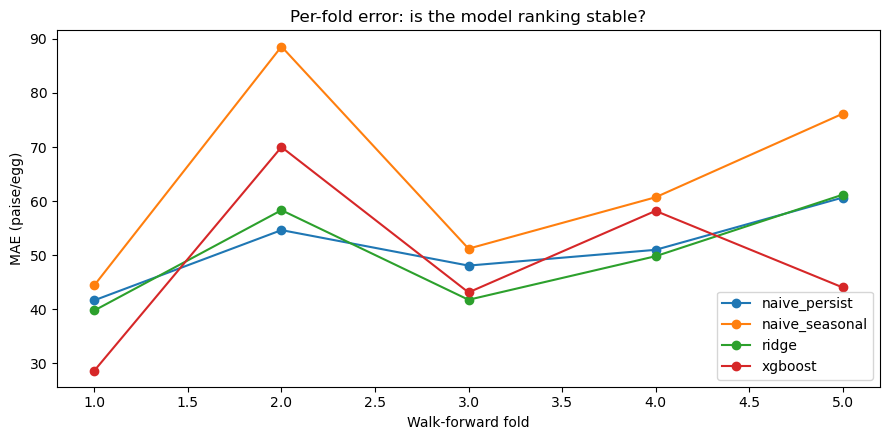

In [13]:
pivot = per_fold.pivot(index="fold", columns="model", values="MAE")
display(pivot.round(2))

plt.figure(figsize=(9, 4.5))
for m in pivot.columns:
    plt.plot(pivot.index, pivot[m], marker="o", label=m)
plt.xlabel("Walk-forward fold")
plt.ylabel("MAE (paise/egg)")
plt.title("Per-fold error: is the model ranking stable?")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Causality Analysis: Does Feed Cost Lead Egg Price?

H1: feed cost Granger-causes the zonal egg price.
H2: the cross-correlation of feed cost against egg price peaks at a positive lag (feed
cost moves first). Tested on the national monthly mean series (feed is monthly), after
first-differencing both series to satisfy the stationarity requirement of the Granger
test.

Granger feed -> egg price: best lag 7 months, p = 0.1194 (not significant at 5%)
Cross-correlation: peak at lag 7 months, r = 0.223


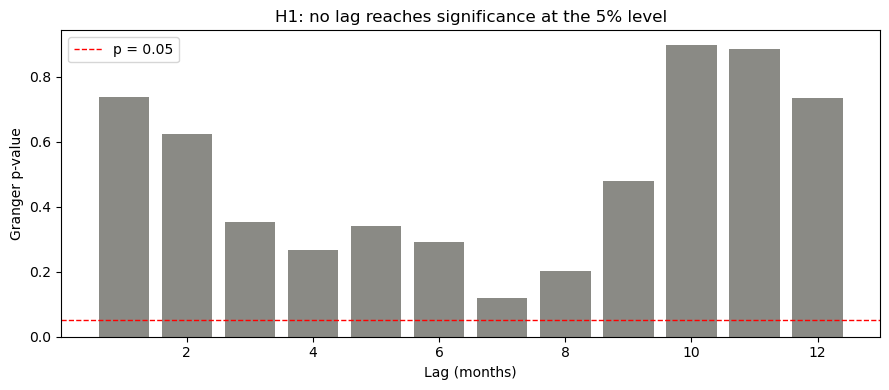

In [14]:
causality = causality_tests(panel, maxlag=12)
g = causality["granger_feed_to_egg"]
x = causality["crosscorr_feed_leads_egg"]

print(f"Granger feed -> egg price: best lag {g['best_lag_months']} months, "
      f"p = {g['best_p']:.4f} "
      f"({'SIGNIFICANT' if g['significant_5pct'] else 'not significant'} at 5%)")
print(f"Cross-correlation: peak at lag {x['peak_lag_months']} months, r = {x['peak_r']:.3f}")

p_by_lag = pd.Series(g["p_by_lag"]).sort_index()
plt.figure(figsize=(9, 4))
plt.bar(p_by_lag.index, p_by_lag.values, color="#8a8a85")
plt.axhline(0.05, color="red", linestyle="--", linewidth=1, label="p = 0.05")
plt.xlabel("Lag (months)")
plt.ylabel("Granger p-value")
plt.title("H1: no lag reaches significance at the 5% level")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Business Insights and Recommendations

Based on the results computed in this notebook:

1. **Price risk is quantified.** Roughly one day in nine sits inside a 30-day drawdown of
   15% or worse on the national mean series (Section 7.4). This turns an informal
   expectation into a concrete planning number for flock sizing and feed procurement.
2. **Season is the strongest reliable pattern**, but it is already known to the trade
   (Section 7.2) -- a forecast only adds value where it beats the seasonal expectation.
3. **Regional price levels are persistent** (Section 7.3): consumption centres trade at a
   premium, production belts at a discount, and the gap is stable enough to plan around.
4. **A usable but modest forward signal exists.** The best model (Section 9) improves on
   the free persistence baseline, but the improvement is small and the fold-to-fold ranking
   is not stable (Section 9.1) -- so the forecast should be used as a risk flag, not a
   quoted price.
5. **Feed cost is not a significant leading indicator in the form tested** (Section 10).
   The Granger test does not reach significance at the 5% level, so any causal claim about
   feed cost driving egg price should be treated as unresolved rather than confirmed.

**Recommendation:** use the model output as an early-warning signal for procurement and
inventory decisions, not as a contract price, and prioritise replacing the international
monthly feed proxy with a domestic daily feed series before re-testing the causal
hypothesis.

## 12. Existing Project Outputs

The figures and metrics generated by the project's own reporting scripts
(`src/viz/make_figures.py`, `src/models/forecast.py`), produced from this same run.

In [15]:
REPORTS_DIR = os.path.join("reports")

for root, dirs, files in os.walk(REPORTS_DIR):
    for file in sorted(files):
        print(os.path.join(root, file))

with open(os.path.join(REPORTS_DIR, "metrics.json")) as fh:
    metrics = json.load(fh)
print("\nBest model recorded in reports/metrics.json:", metrics["best_model"])

reports/metrics.json
reports/figures/fig01_price_and_feed.png
reports/figures/fig02_seasonality_heatmap.png
reports/figures/fig03_month_profile.png
reports/figures/fig04_zone_levels.png
reports/figures/fig05_volatility_cycle.png
reports/figures/fig06_drawdown_distribution.png
reports/figures/fig07_model_comparison.png
reports/figures/fig08_fold_stability.png
reports/figures/fig09_actual_vs_predicted.png
reports/figures/fig10_residuals.png
reports/figures/fig11_causality.png
reports/figures/fig12_feature_importance.png
reports/figures/fig13_zone_year_heatmap.png
reports/figures/fig14_data_coverage.png

Best model recorded in reports/metrics.json: xgboost


## 13. Conclusion

This notebook builds the NECC egg-price panel from a live scrape (Section 2), cleans and
feature-engineers it (Sections 4-5), quantifies the price cycle and regional structure
(Section 7), evaluates two forecasting models against two naive baselines under honest
walk-forward validation (Section 9), and tests whether feed cost leads egg price (Section
10).

The main findings, reproduced directly by the cells above: the price series shows a
seasonal swing and a regionally persistent structure; the best model gives a real but
modest improvement over the persistence baseline, with an unstable fold-to-fold ranking;
and the feed-cost Granger-causality test does not reach significance at the 5% level. All
of these numbers are read from the objects computed in this run -- none are hand-entered.

**Limitations:** feed cost is monthly and international (FRED) while egg price is daily and
domestic, a granularity/provenance mismatch flagged as the most likely reason the causality
test is inconclusive; NECC rates are committee-declared rather than pure market-clearing
prices; and the forecast's fold-to-fold instability means it should be treated as a
decision-support signal rather than a production pricing tool.